In [3]:
import pathlib
import sys
import os

# Hacky way to get to root package
if "notebooks" in os.getcwd():
    os.chdir("..")

In [4]:
%load_ext autoreload
%autoreload 2
    
import sys
from data_container import load_scouted_data
import pandas as pd
import plotly.express as px
pd.set_option('display.max_columns', None)

In [5]:
scouted_data = load_scouted_data()
scouted_data['Team and Robot'] = scouted_data['Team and Robot'].astype(str)
scouted_data

,Scouter Initials,Match Number,Team and Robot,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,XXXXXX
0,abc,1,340,True,0,0,1,4,0,1,1,0,28,14,28,27,22,12,6,3,False,False,2,1,NaN
1,abc,1,3504,False,0,0,1,0,2,1,0,1,22,6,19,4,23,16,20,15,False,False,0,0,NaN
2,abc,1,3015,False,4,2,1,2,0,0,1,0,10,19,23,12,30,12,16,12,False,False,1,1,NaN
3,abc,1,2641,False,2,0,1,3,4,2,1,2,4,10,3,18,26,15,10,7,False,False,0,0,NaN
4,abc,1,3990,False,3,1,3,1,1,0,2,2,2,4,13,1,29,0,19,7,False,False,3,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,abc,32,10582,False,1,0,5,3,1,1,2,1,5,2,20,14,14,4,6,19,False,False,1,0,NaN
164,abc,32,1708,False,3,1,0,3,1,0,1,0,14,14,15,6,18,9,5,0,False,False,0,1,NaN
165,abc,32,11456,False,0,0,2,2,3,0,1,2,12,7,1,9,3,11,13,0,False,False,2,1,NaN
166,abc,32,8705,False,4,2,4,2,4,1,2,2,12,2,9,2,25,15,11,3,False,True,1,1,NaN


In [6]:
team_averages = scouted_data.groupby("Team and Robot").mean(numeric_only=True)
team_averages

,Match Number,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,XXXXXX
Team and Robot,,,,,,,,,,,,,,,,,,,,,,,
10300,21.666667,0.000000,1.666667,0.333333,2.666667,1.000000,1.333333,0.666667,1.666667,1.333333,24.333333,9.333333,12.666667,14.000000,18.666667,12.333333,10.000000,16.666667,0.000000,0.000000,0.666667,0.000000,NaN
10512,22.333333,0.333333,2.333333,0.666667,2.666667,1.333333,2.666667,1.666667,1.000000,1.000000,9.000000,12.666667,23.666667,14.000000,17.000000,8.333333,9.000000,12.666667,0.000000,0.000000,0.333333,0.000000,NaN
10513,22.333333,0.000000,3.000000,0.666667,3.333333,2.000000,1.333333,1.666667,0.333333,1.000000,3.666667,13.333333,12.666667,10.333333,8.000000,7.000000,4.666667,14.666667,0.000000,0.000000,2.000000,0.666667,NaN
10515,21.666667,0.000000,2.666667,0.000000,1.000000,2.333333,2.000000,1.333333,0.333333,1.000000,13.666667,5.666667,22.333333,15.666667,14.000000,10.666667,14.000000,12.333333,0.000000,0.000000,2.000000,0.333333,NaN
10516,18.000000,0.000000,2.500000,1.500000,2.500000,3.000000,3.000000,0.000000,1.500000,1.500000,6.000000,13.000000,22.000000,19.500000,13.000000,11.000000,11.500000,3.500000,0.000000,0.000000,2.000000,0.500000,NaN
10517,22.333333,0.000000,0.666667,1.333333,2.000000,4.000000,2.000000,0.666667,0.666667,1.000000,12.666667,16.666667,12.333333,17.000000,10.000000,14.000000,8.333333,7.333333,0.000000,0.000000,2.666667,0.666667,NaN
10582,23.666667,0.333333,1.333333,0.333333,4.000000,3.333333,1.000000,1.666667,1.666667,1.000000,10.666667,9.000000,14.333333,15.333333,12.000000,7.000000,2.666667,17.666667,0.000000,0.000000,1.000000,0.333333,NaN
11456,24.000000,0.000000,0.666667,0.333333,3.000000,1.666667,1.666667,0.666667,0.666667,1.333333,19.000000,10.000000,19.666667,15.333333,8.333333,13.000000,6.333333,7.666667,0.000000,0.000000,1.666667,0.333333,NaN
117,17.500000,0.000000,2.500000,0.500000,3.250000,1.500000,3.750000,0.500000,0.500000,1.750000,16.500000,9.750000,14.500000,18.750000,8.250000,8.000000,8.750000,11.500000,0.250000,0.250000,1.000000,0.500000,NaN


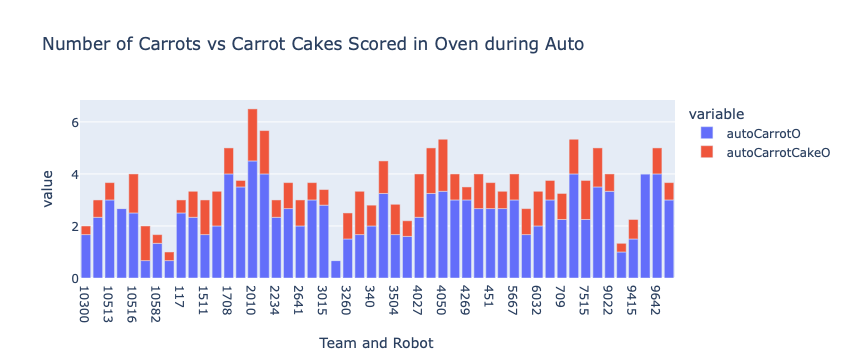

In [7]:
fig = px.bar(team_averages, y=["autoCarrotO", "autoCarrotCakeO"], title = "Number of Carrots vs Carrot Cakes Scored in Oven during Auto")
fig

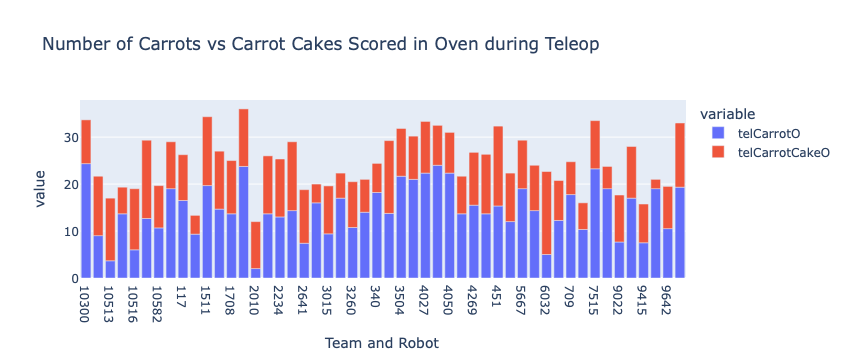

In [8]:
fig = px.bar(team_averages, y=["telCarrotO", "telCarrotCakeO"], title = "Number of Carrots vs Carrot Cakes Scored in Oven during Teleop")
fig

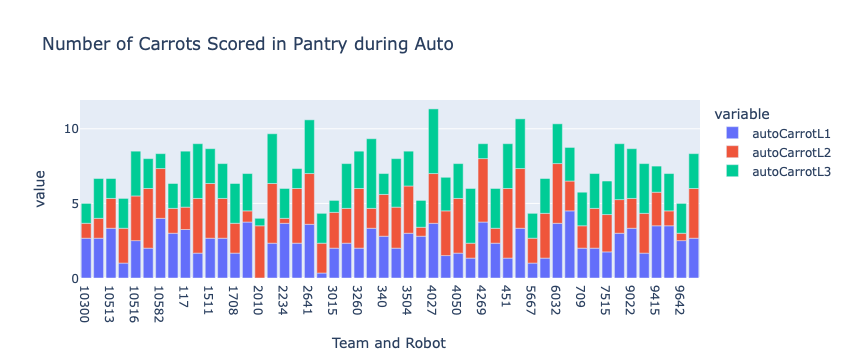

In [9]:
fig = px.bar(team_averages, y=["autoCarrotL1", "autoCarrotL2", "autoCarrotL3"], title="Number of Carrots Scored in Pantry during Auto")
fig

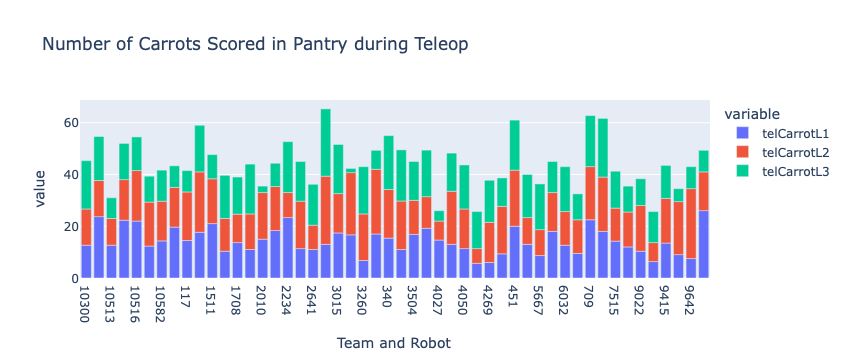

In [10]:
fig = px.bar(team_averages, y=["telCarrotL1", "telCarrotL2", "telCarrotL3"], title="Number of Carrots Scored in Pantry during Teleop")
fig

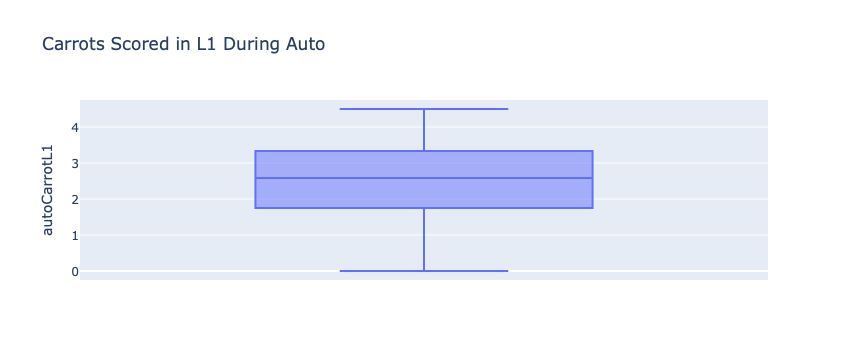

In [13]:
fig = px.box(team_averages, y="autoCarrotL1", title="Carrots Scored in L1 During Auto")
fig

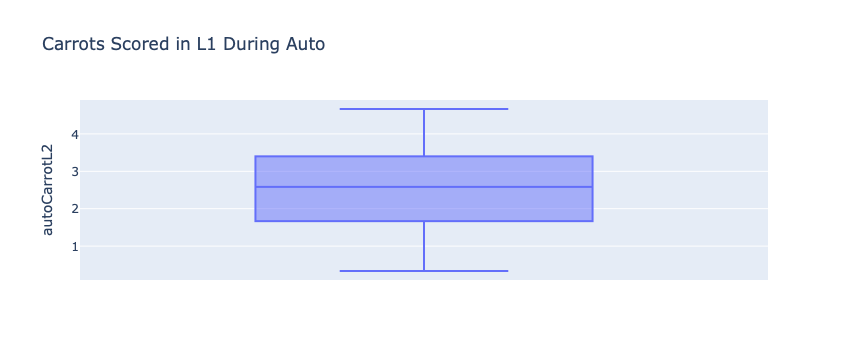

In [14]:
fig = px.box(team_averages, y="autoCarrotL2", title="Carrots Scored in L2 During Auto")
fig

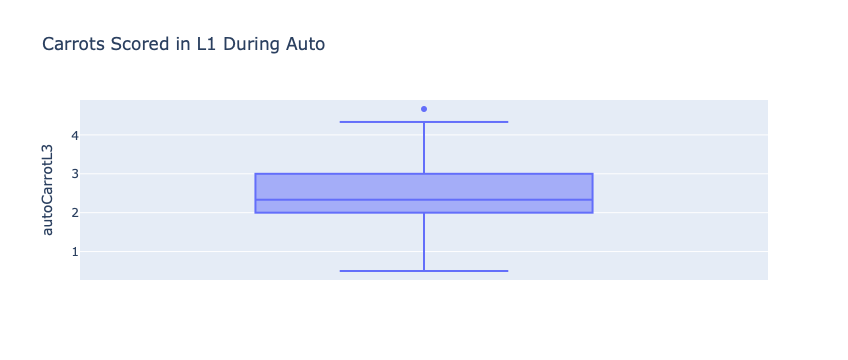

In [15]:
fig = px.box(team_averages, y="autoCarrotL3", title="Carrots Scored in L3 During Auto")
fig

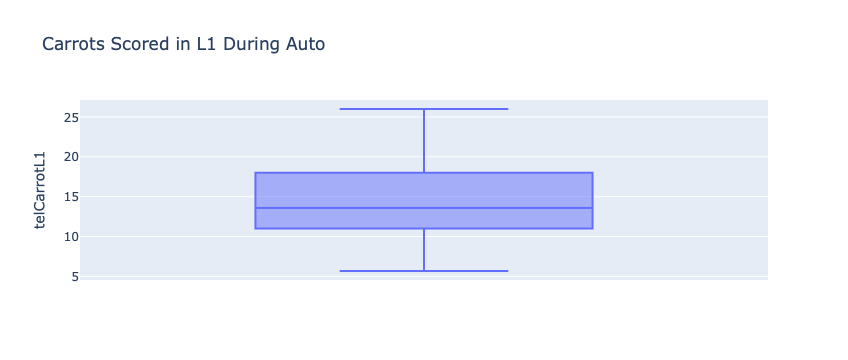

In [17]:
fig = px.box(team_averages, y="telCarrotL1", title="Carrots Scored in L1 During Teleop")
fig

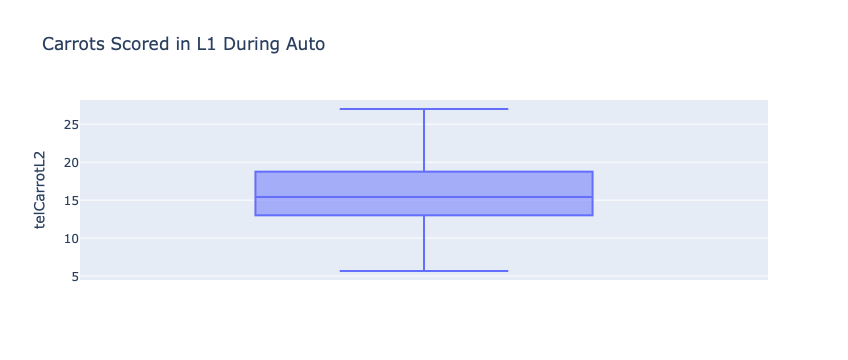

In [18]:
fig = px.box(team_averages, y="telCarrotL2", title="Carrots Scored in L2 During Teleop")
fig

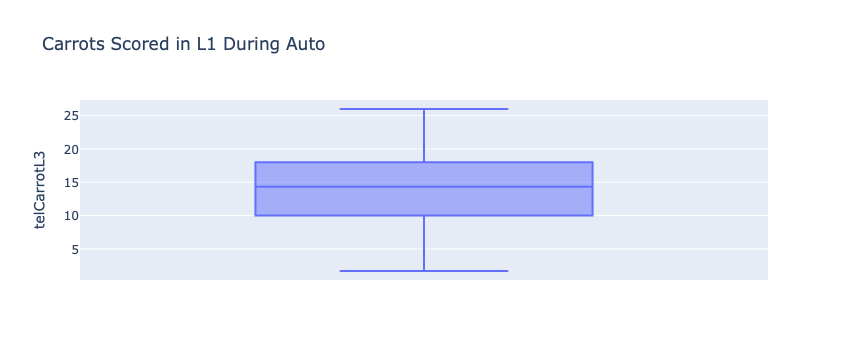

In [19]:
fig = px.box(team_averages, y="telCarrotL3", title="Carrots Scored in L3 During Teleop")
fig